In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
RANDOM_STATE = 24  # Remember to remove at the time of promotion to production(RANDOM_STATE = None) 
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
N_EPOCHS = 20000 # Number of Epochs
ALPHA = .001  # Learning Rate 
N_SAMPLES = 1000  # number of sample to create
TEST_SIZE = 0.2

params = {
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium'
}
plt.rcParams.update(params)
CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') # plt.style.use('ggplot')

In [3]:
def plot_decison_boundary(model:dict, 
                          X_tr:np.ndarray,
                          y_tr:np.ndarray,
                          X_ts:np.ndarray,
                          y_ts:np.ndarray ):
    
    fig, ax = plt.subplots()
    dm = 0.01
    margin = 10 * dm
    X_min = min(X_tr[:,0].min() - margin, X_ts[:,0].min() - margin)
    X_max = max(X_tr[:,0].max() + margin, X_ts[:,0].max() + margin)
    y_min = min(X_tr[:,1].min() - margin, X_ts[:,1].min() - margin)
    y_max = max(X_tr[:,1].max() + margin, X_ts[:,1].max() + margin)

    xx, yy = np.meshgrid(np.arange(X_min, X_max, dm),
            np.arange(y_min, y_max, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]
    Z = fn_predict(model, XX).reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:,0], X_tr[:,1], c=y_tr, s=30, edgecolors='k', cmap=CMAP)
    ax.scatter(X_ts[:,0], X_ts[:,1], c=y_ts, s=30, marker='*', edgecolors='k', cmap=plt.cm.seismic)

    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

In [4]:

from sklearn.datasets import load_iris

import pandas as pd

# Load the dataset as a Bunch object (dictionary-like)
iris = load_iris()

# Access data (X) and target labels (y)
X = iris.data    # 150x4 NumPy array
y = iris.target  # 150-element NumPy vector

# Optional: Load directly into a clean Pandas DataFrame
data_df = pd.DataFrame(iris.data, columns=iris.feature_names)
data_df['species'] = iris.target
data_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=TEST_SIZE,
                                                   random_state=RANDOM_STATE,
                                                    stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

In [6]:
def fn_sigmoid(z):
    return 1/(1+np.exp(-z))

In [7]:
def fn_softmax(z):
    # Subtract max for numerical stability
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [8]:
def fn_active(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)

def fn_active_prime(z: np.ndarray) -> np.ndarray:
    return 1.0-np.tanh(z)**2

In [9]:
fn_active(np.asarray([[-1, 0, 1],[-np.inf, 0, np.inf]]))

array([[-0.76159416,  0.        ,  0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [10]:
def fn_predict(model: dict, X_p: np.ndarray):
    ''' 
    model : Dictionary containing weights and bias
    X : input features
    '''
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']

    # forward Propagation
    # Layer 1
    z1 = X_p.dot(W1) + b1 # Aggeragation
    a1 = fn_active(z1)

    # Layer 2
    z2 = a1.dot(W2) + b2 # Aggeragation
    a2 = fn_sigmoid(z2)
    
    return a2 >= 0.5 

In [11]:
# def fn_calculate_loss(model: dict, X_l: np.ndarray, y_l: np.ndarray):
#     ''' 
#     model : Dictionary containing weights and bias
#     X_l : input features
#     y_l : target
#     '''
#     m = X_l.shape[0]
#     W1, W2 = model['W1'], model['W2']
#     b1, b2 = model['b1'], model['b2']

#     # forward Propagation
#     # Layer 1
#     z1 = X_l.dot(W1) + b1 # Aggeragation
#     a1 = fn_active(z1)

#     # Layer 2
#     z2 = a1.dot(W2) + b2 # Aggeragation
#     a2 = fn_sigmoid(z2)

#     data_loss = -(y_l * np.log(a2) + (1 - y_l) * np.log(1 - a2)).sum()
#     return data_loss/m
def fn_calculate_loss(model: dict, X_l: np.ndarray, y_l: np.ndarray):
    m = X_l.shape[0]
    W1, W2 = model['W1'], model['W2']
    b1, b2 = model['b1'], model['b2']
    
    z1 = X_l.dot(W1) + b1
    a1 = fn_active(z1)
    z2 = a1.dot(W2) + b2
    a2 = fn_softmax(z2)
    
    eps = 1e-15
    a2 = np.clip(a2, eps, 1 - eps)
    
    # Categorical cross-entropy loss
    data_loss = -np.sum(y_l * np.log(a2))
    return data_loss / m

In [12]:
def fn_build_model( nn_hdim: np.int64,
                    X: np.ndarray,
                    y: np.ndarray,
                    alpha: np.float64 = ALPHA,
                    n_epochs: np.int64 = N_EPOCHS
                  ) -> dict:
    '''
    nn_hdim: Numer of hidden units 
    X: features
    y: labels
    alpha: Learning Rate
    n_epochs: Number of passes through complete data for gradient decent
    '''
    m, nn_input_dim = X.shape
    nn_output_dim = y.shape[1]   

    w1 = rng.random((nn_input_dim, nn_hdim), dtype = np.float32) / np.sqrt(nn_input_dim)
    w2 = rng.random((nn_hdim, nn_output_dim), dtype = np.float32) / np.sqrt(nn_hdim)

    b1 = np.zeros((1,nn_hdim), dtype = np.float32)
    b2 = np.zeros((1,nn_output_dim), dtype = np.float32)

    curr_loss = 0
    loss, epoch = [], []

    for i in range(n_epochs):  # loop for number of epochs
        # forward Propagation
        # Layer 1        
        z1 = X.dot(w1) + b1 # Aggeragation
        a1 = fn_active(z1)
        
        # Layer 2
        z2 = a1.dot(w2) + b2 # Aggeragation
        a2 = fn_sigmoid(z2)

        # Back propagation
        # Layer 2
        dz2 = a2 - y
        dw2 = (a1.T).dot(dz2)
        assert (w2.shape == dw2.shape), f'Shape -> W2: {w2.shape} | dw2: {dw2.shape}'

        db2 = np.sum(dz2, axis=0, keepdims=True)
        assert (b2.shape == db2.shape), f'Shape -> b2: {b2.shape} | db2: {db2.shape}'

        da1 = dz2.dot(w2.T)
        assert (a1.shape == da1.shape), f'Shape -> a1: {a1.shape} | da1: {da1.shape}'

        # Layer 1
        dz1 = da1 * fn_active_prime(z1)
        
        dw1 = (X.T).dot(dz1)
        assert (w1.shape == dw1.shape), f'Shape -> W1: {w1.shape} | dw1: {dw1.shape}'

        db1 = np.sum(dz1, axis=0, keepdims=True)
        assert (b1.shape == db1.shape), f'Shape -> b1: {b1.shape} | db1: {db1.shape}'

        # Gradient Update 
        w1 = w1 - alpha * dw1 / m
        w2 = w2 - alpha * dw2 / m
        b1 = b1 - alpha * db1 / m
        b2 = b2 - alpha * db2 / m

        model = {'W1': w1, 'W2': w2, 'b1': b1, 'b2': b2}

        if i % 100 == 0:
            curr_loss = fn_calculate_loss(model = model, X_l = X, y_l = y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f'Epoch {i:3d} : Loss = {curr_loss:.4f}')

    loss_hist['epoch'] = epoch
    loss_hist['loss'] = loss
    return model

In [13]:
loss_hist = {'epoch':[],
            'loss':[]}
y_train = y_train.reshape(-1, 1)
model = fn_build_model(32, X_train, y_train)

Epoch   0 : Loss = 0.0000
Epoch 100 : Loss = 0.0000
Epoch 200 : Loss = 0.0000
Epoch 300 : Loss = 0.0000
Epoch 400 : Loss = 0.0000
Epoch 500 : Loss = 0.0000
Epoch 600 : Loss = 0.0000
Epoch 700 : Loss = 0.0000
Epoch 800 : Loss = 0.0000
Epoch 900 : Loss = 0.0000
Epoch 1000 : Loss = 0.0000
Epoch 1100 : Loss = 0.0000
Epoch 1200 : Loss = 0.0000
Epoch 1300 : Loss = 0.0000
Epoch 1400 : Loss = 0.0000
Epoch 1500 : Loss = 0.0000
Epoch 1600 : Loss = 0.0000
Epoch 1700 : Loss = 0.0000
Epoch 1800 : Loss = 0.0000
Epoch 1900 : Loss = 0.0000
Epoch 2000 : Loss = 0.0000
Epoch 2100 : Loss = 0.0000
Epoch 2200 : Loss = 0.0000
Epoch 2300 : Loss = 0.0000
Epoch 2400 : Loss = 0.0000
Epoch 2500 : Loss = 0.0000
Epoch 2600 : Loss = 0.0000
Epoch 2700 : Loss = 0.0000
Epoch 2800 : Loss = 0.0000
Epoch 2900 : Loss = 0.0000
Epoch 3000 : Loss = 0.0000
Epoch 3100 : Loss = 0.0000
Epoch 3200 : Loss = 0.0000
Epoch 3300 : Loss = 0.0000
Epoch 3400 : Loss = 0.0000
Epoch 3500 : Loss = 0.0000
Epoch 3600 : Loss = 0.0000
Epoch 3700 

In [14]:
y_pred = fn_predict(model = model, X_p = X_train)
accuracy_score(y_train, y_pred)

0.6666666666666666

In [15]:
y_pred = fn_predict(model = model, X_p = X_test)
accuracy_score(y_test, y_pred)

0.6666666666666666

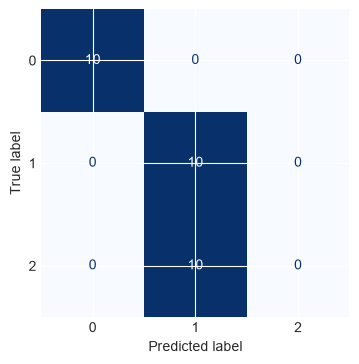

In [17]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1,2])
fig, ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax,cmap='Blues',colorbar=False)

ValueError: shapes (98800,2) and (4,32) not aligned: 2 (dim 1) != 4 (dim 0)

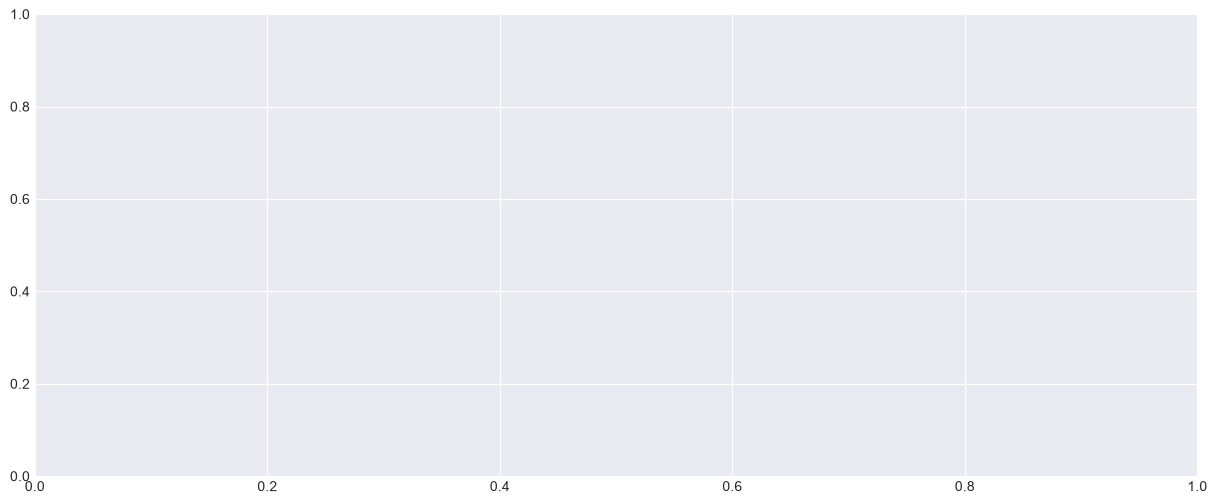

In [18]:
plot_decison_boundary(model,X_train,y_train,X_test,y_test)